# CPU Energy Corrections

This notebook contains every correction applied to the **CPU and DRAM energy** recorded by the main experiment (`results/main`). The **GPU energy is not affected** by any of them: it was measured correctly for every inference and is never modified here.

Two problems were found in the version of `evaluate_from_local.py` used to run the experiment:

| | Problem | Kind of fix |
|---|---|---|
| **Fix 1** | The RAPL counter overflow was handled with the wrong counter size, so long inferences lost part of their CPU energy. | Exact reconstruction of the lost energy |
| **Fix 2** | Only the first of the server's two processors was measured. | Estimate, based on the `cpu_power_profile` experiment |

The notebook goes from the values originally recorded to the final ones:

1. Load each run and restore the originally recorded values
2. Fix 1: reconstruct the energy lost to the counter overflow
3. Fix 2: estimate the energy of the second processor
4. Recompute the summary of each run
5. Write the per-prompt records, the `run_data.json` files and the `run_table.csv`
6. Validate the results

**The notebook can be run any number of times.** The originally recorded values are kept inside the corrected records, so every execution starts again from them, regardless of whether the data on disk has already been corrected.

Both problems are fixed in the current version of `evaluate_from_local.py`, which handles the overflow correctly and measures both processors. Runs produced by it do not need these corrections.

## 1. Setup

With `APPLY = False`, the notebook computes everything and reports what would change, without writing anything.

In [1]:
import csv
import json
import math
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path("..").resolve()

# Results of the main experiment, corrected in place
RESULTS_DIR = ROOT_DIR / "results/main"
# Results of the experiment that measured the power of both processors (experiments/cpu-power-profile)
PROFILE_RESULTS = ROOT_DIR / "results/cpu_power_profile/run_table.csv"

# Write the corrected values to disk
APPLY = True

# Size the script wrongly assumed for the RAPL counters (µJ)
M = 2**32
# Actual size of the RAPL counters of the server (µJ), from /sys/class/powercap/intel-rapl:*/max_energy_range_uj
MAX_ENERGY_RANGE_UJ = 262143328850

# Measured fields of each per-prompt record
CPU_FIELD = "inference_cpu_joules"
DRAM_FIELD = "inference_dram_joules"
GPU_FIELD = "inference_gpu_joules"
TOTAL_FIELD = "total_inference_joules"
TIME_FIELD = "inference_time_seconds"

# Fields added by the corrections
CORRECTION_FIELD = "rapl_correction"                 # Fix 1: originally recorded value and what was restored
CPU1_FIELD = "inference_cpu1_joules_estimated"       # Fix 2: estimated energy of the second processor
DRAM1_FIELD = "inference_dram1_joules_estimated"     # Fix 2: estimated energy of the DRAM of the second processor

## 2. Loading the runs and restoring the recorded values

Each run directory contains one JSON file per MMLU-Pro subject, with one record per question, and a `run_data.json` file with the summary of the run.

Before applying any correction, every record is brought back to the state in which it was originally recorded:

- Fix 1 corrects `inference_cpu_joules` and `inference_dram_joules` in place, and keeps the value originally recorded in the `rapl_correction` field of the record (`stored_joules`). Records with this field are restored from it. Records without it were never changed by Fix 1.
- The fields estimated by Fix 2 are removed.
- The total energy is recomputed as it was originally: CPU + DRAM + GPU.

This is what makes the notebook safe to run more than once.

In [2]:
def run_directories():
    directories = [d for d in RESULTS_DIR.glob("run_*") if d.is_dir()]
    # run_<model index>_repetition_<repetition index>
    return sorted(directories, key=lambda d: tuple(int(x) for x in d.name.split("_")[1::2]))


def load_run(run_dir):
    # Returns {file path: records} with the per-prompt records of a run, and its summary
    files = {}
    for path in sorted(run_dir.glob("*/CoT/all/*.json")):
        with open(path, "r") as f:
            files[path] = json.load(f)
    with open(run_dir / "run_data.json", "r") as f:
        run_data = json.load(f)
    return files, run_data


def restore_recorded_values(record):
    correction = record.pop(CORRECTION_FIELD, {})
    if "cpu" in correction:
        record[CPU_FIELD] = correction["cpu"]["stored_joules"]
    if "dram" in correction:
        record[DRAM_FIELD] = correction["dram"]["stored_joules"]

    record.pop(CPU1_FIELD, None)
    record.pop(DRAM1_FIELD, None)

    record[TOTAL_FIELD] = record[CPU_FIELD] + record[DRAM_FIELD] + record[GPU_FIELD]


print(f"Runs found: {len(run_directories())}")

Runs found: 530


## 3. Fix 1: RAPL counter overflow

### The problem

The energy of an inference is the difference between two readings of a counter that only goes up. These counters have a limited size: when they reach their maximum, $R$, they start again from zero. On this server, $R = 262{,}143{,}328{,}850$ µJ (about 262 kJ).

The script tried to handle this by computing the difference as `(end - start) % 2**32`, assuming the counters had $M = 2^{32}$ µJ (about 4,295 J) of range. Since that is not their actual size, two things went wrong:

- **Long inferences were truncated.** Any inference that used more than 4,295 J lost one or more multiples of $M$. At the CPU's usual 87 W, this affects every inference longer than about 50 seconds.
- **Real overflows were corrected by the wrong amount.**

### What can be recovered

For a recorded value $s$, the true energy is one of:

$$\text{true} = s + k \cdot M \qquad \text{(the counter did not overflow during the inference)}$$
$$\text{true} = s + (R \bmod M) + k \cdot M \qquad \text{(the counter overflowed once during the inference)}$$

where $k$ is the number of lost multiples of $M$.

**Finding $k$.** Within a run, the CPU power is very stable (it varies by about 1%). The energy of an inference should therefore be close to the run's usual power multiplied by the inference time. Since candidates with different $k$ are 4,295 J apart, the one closest to that expected value is unambiguous.

**The overflow case cannot be identified in general.** Its candidates are only $R \bmod M \approx 150$ J away from the others, which is within the normal variation between inferences. It is only assumed when the recorded value is impossible otherwise: a short inference recorded with more than 4,000 J. This happens when the counter overflows during an inference that used less than 150 J. Overflows that go undetected leave the value about 150 J too low, at most once for every 262 kJ consumed.

### The reference power of a run

The usual power of a run cannot be taken as a simple median of energy divided by time, because in some runs most of the recorded values are truncated. Instead, the reference power is the one that agrees with the largest number of recorded values *modulo* $M$: a value $s$ recorded in time $t$ agrees with a power $P$ when $P \cdot t$ is close to $s + k \cdot M$ for some $k$.

In [3]:
R_MOD_M = MAX_ENERGY_RANGE_UJ % M


def reference_power(records, field):
    # Recorded energy (µJ) and time of every inference long enough to give a stable power reading
    timed = [(r[field] * 1e6, r[TIME_FIELD]) for r in records if r[TIME_FIELD] >= 1]

    def distance(s, t, power):
        d = (power * t * 1e6 - s) % M
        return min(d, M - d)

    def agreeing(power):
        return [(s, t) for s, t in timed if distance(s, t, power) < 0.05 * power * t * 1e6 + 20e6]

    # Candidate powers: the ones given by the recorded values themselves, rounded to 0.5 W
    candidates = {round(s / t / 1e6 * 2) / 2 for s, t in timed if s > 0}
    best = max(candidates, key=lambda power: len(agreeing(power)))

    # Median power of the agreeing values, after restoring their lost multiples of M
    return statistics.median((s + round((best * t * 1e6 - s) / M) * M) / t / 1e6 for s, t in agreeing(best))


def correct_overflow(recorded_joules, time_seconds, power):
    s = round(recorded_joules * 1e6)
    expected = power * time_seconds * 1e6

    # The counter did not overflow: restore the k lost multiples of M
    k = max(0, round((expected - s) / M))
    value, overflowed = s + k * M, False
    error = abs(value - expected)

    # The counter overflowed during an inference of less than R mod M: the recorded value is about M too high
    overflow_value = s + R_MOD_M - M
    if error > 0.5 * M and overflow_value >= 0 and abs(overflow_value - expected) < 0.1 * error:
        value, overflowed, k = overflow_value, True, -1
        error = abs(value - expected)

    return {
        "joules": value / 1e6,
        "k": k,
        "overflowed": overflowed,
        "expected_joules": expected / 1e6,
        # Distance to the expected value, as a fraction of M. A wrong k would be about 1.
        "error_fraction": error / M,
    }


def apply_overflow_fix(records):
    # Corrects the CPU and DRAM energy of every record of a run. Returns the corrections made.
    log = []
    powers = {"cpu": reference_power(records, CPU_FIELD), "dram": reference_power(records, DRAM_FIELD)}

    for record in records:
        correction = {}
        for domain, field in (("cpu", CPU_FIELD), ("dram", DRAM_FIELD)):
            result = correct_overflow(record[field], record[TIME_FIELD], powers[domain])
            if result["k"] != 0:
                correction[domain] = {"stored_joules": record[field], "wrapped": int(result["overflowed"]), "k": result["k"]}
                log.append({
                    "question_id": record["question_id"],
                    "domain": domain,
                    "inference_time_seconds": record[TIME_FIELD],
                    "stored_joules": record[field],
                    "corrected_joules": result["joules"],
                    "expected_joules": round(result["expected_joules"], 3),
                    "wrapped": int(result["overflowed"]),
                    "k": result["k"],
                    "error_fraction": round(result["error_fraction"], 3),
                })
                record[field] = result["joules"]

        if correction:
            record[TOTAL_FIELD] = record[CPU_FIELD] + record[DRAM_FIELD] + record[GPU_FIELD]
            # Keeps the originally recorded values, so the correction can be traced and reverted
            record[CORRECTION_FIELD] = correction

    return log, powers

## 4. Fix 2: energy of the second processor

### The problem

The server has **two processors**, each with its own RAPL counters: one for the processor itself and one for the DRAM attached to it. The script only read the counters of the first processor, so the energy of the second one, and of its DRAM, was never measured.

### What the `cpu_power_profile` experiment shows

The `experiments/cpu-power-profile` experiment measures the power of both processors, and of their DRAM, every second, while an instruct model and a reasoning model are evaluated with the same configuration as in the main experiment. Each model answers a subset of the benchmark chosen so that its inference phase lasts five to six minutes, and every run is repeated three times, so all models contribute the same amount of data. It shows that, during inference, the two processors are always in one of two states:

- the processor **running the inference process** draws more power (the *busy* state);
- the **other** processor draws less.

The operating system can move the process from one processor to the other, in which case the two simply swap states. The DRAM of the second processor draws a constant power.

The cells below read these values directly from the results of that experiment. Each model is first averaged over its repetitions, and the values used by the estimate are the average of the models. The standard deviation over the repetitions shows how much the runs of the same model differ, to compare with how much the models differ from each other.

In [4]:
if not PROFILE_RESULTS.exists():
    raise FileNotFoundError(
        f"{PROFILE_RESULTS} not found. Run the experiment first, from the root of the repository:\n"
        "    python experiment-runner/ experiments/cpu-power-profile/RunnerConfig.py"
    )

profile = pd.read_csv(PROFILE_RESULTS)
profile[["workload", "phase", "duration_seconds", "cpu0_watts", "cpu1_watts", "dram0_watts", "dram1_watts", "cpu_busy_watts", "cpu_other_watts", "package0_busy_share"]]

,workload,phase,duration_seconds,cpu0_watts,cpu1_watts,dram0_watts,dram1_watts,cpu_busy_watts,cpu_other_watts,package0_busy_share
0,idle,idle,299.399227,62.139814,60.128011,11.899793,12.027674,62.139814,60.128011,1.000000
1,Qwen/Qwen2.5-3B-Instruct,inference,10.006989,86.569908,102.092828,11.886423,12.258458,102.092828,86.569908,0.000000
2,mistralai/Ministral-3-8B-Reasoning-2512,inference,367.274477,97.640832,86.746960,11.930069,12.138099,98.016599,86.697050,0.599455


In [ ]:
inference_profile = profile[profile["phase"] == "inference"]
states = ["cpu_busy_watts", "cpu_other_watts", "dram1_watts"]

# Runs with too little data to give a reliable power (see MIN_INFERENCE_SECONDS in the experiment)
short_runs = inference_profile[inference_profile["duration_seconds"] < 300]
if len(short_runs) > 0:
    print(f"WARNING: {len(short_runs)} run(s) with less than 300 s of inference:")
    print(short_runs[["__run_id", "workload", "duration_seconds"]].to_string(index=False), "\n")

# Each model averaged over its repetitions, and how much its repetitions differ
by_model = inference_profile.groupby("workload")
per_model = by_model[states].mean()
print("Average of each model (W):")
print(per_model.assign(runs=by_model.size(), inference_seconds=by_model["duration_seconds"].sum()).round(2).to_string())
print("\nStandard deviation between the runs of each model (W):")
print(by_model[states].std().round(2).to_string())

# Power of the processor running the inference process, of the other processor, and of the DRAM of the second processor
BUSY_WATTS = float(per_model["cpu_busy_watts"].mean())
OTHER_WATTS = float(per_model["cpu_other_watts"].mean())
DRAM1_WATTS = float(per_model["dram1_watts"].mean())

print(f"\nBusy processor:  {BUSY_WATTS:.2f} W")
print(f"Other processor: {OTHER_WATTS:.2f} W")
print(f"DRAM of the second processor: {DRAM1_WATTS:.2f} W")

# The estimate assumes these values do not depend on the model. This shows how much they differ between the profiled models.
print("\nRange across the profiled models:")
print(per_model.agg(["min", "max"]).round(2).to_string())

### The estimate

The first processor was measured, so its state during each inference is known: its energy divided by the inference time gives its power, which is either close to the *busy* value or to the *other* value. The second processor is then in the opposite state:

$$E_{\text{cpu1}} = \begin{cases} P_{\text{other}} \cdot t & \text{if the first processor was busy} \\ P_{\text{busy}} \cdot t & \text{otherwise} \end{cases} \qquad\qquad E_{\text{dram1}} = P_{\text{dram1}} \cdot t$$

The first processor is considered busy when its power is above the midpoint between the two states. Section 7 confirms, using the data of the main experiment, that the first processor really was in one of these two states in practically every inference, for every model.

The estimates are stored in **separate fields** (`inference_cpu1_joules_estimated` and `inference_dram1_joules_estimated`), so measured and estimated values can always be told apart. They are added to the total energy of each inference.

In [6]:
def apply_second_processor_estimate(records):
    threshold = (BUSY_WATTS + OTHER_WATTS) / 2

    for record in records:
        t = record[TIME_FIELD]
        first_processor_busy = t > 0 and record[CPU_FIELD] / t > threshold

        record[CPU1_FIELD] = (OTHER_WATTS if first_processor_busy else BUSY_WATTS) * t
        record[DRAM1_FIELD] = DRAM1_WATTS * t
        record[TOTAL_FIELD] += record[CPU1_FIELD] + record[DRAM1_FIELD]

## 5. Recomputing the summary of each run

The `run_data.json` file of a run, and its row in `run_table.csv`, are computed from its per-prompt records, in the same way as `evaluate_from_local.py` does. After the corrections:

- The CPU and DRAM totals cover **both processors**: the measured values of the first plus the estimated values of the second. The estimated part is also reported on its own.
- The efficiency metrics based on the **total energy** of the system keep their names (`accuracy_per_joule`, `tokens_per_joule`, `joules_per_token`, `avg_joules_per_inference`).
- The same metrics are added for the **GPU energy** alone (`accuracy_per_gpu_joule`, `tokens_per_gpu_joule`, `gpu_joules_per_token`, `avg_gpu_joules_per_inference`). These only depend on values that were measured directly and needed no correction, and are the ones used in the analysis.

In [7]:
def summarize_run(records, run_data):
    n = len(records)
    cpu0 = sum(r[CPU_FIELD] for r in records)
    dram0 = sum(r[DRAM_FIELD] for r in records)
    cpu1 = sum(r[CPU1_FIELD] for r in records)
    dram1 = sum(r[DRAM1_FIELD] for r in records)
    gpu = sum(r[GPU_FIELD] for r in records)
    total = sum(r[TOTAL_FIELD] for r in records)
    tokens = sum(r["total_tokens"] for r in records)
    time_seconds = sum(r[TIME_FIELD] for r in records)
    accuracy = run_data["avg_accuracy"]

    return {
        # Efficiency on the total energy of the system
        "accuracy_per_joule": accuracy / (total / n),
        "tokens_per_joule": tokens / total,
        "joules_per_token": total / tokens,
        "avg_joules_per_inference": total / n,
        # Energy
        "total_inference_joules": total,
        "total_inference_cpu_joules": cpu0 + cpu1,
        "total_inference_dram_joules": dram0 + dram1,
        "total_inference_gpu_joules": gpu,
        # Power
        "avg_total_power_watts": total / time_seconds,
        "avg_cpu_power_watts": (cpu0 + cpu1) / time_seconds,
        "avg_dram_power_watts": (dram0 + dram1) / time_seconds,
        "avg_gpu_power_watts": gpu / time_seconds,
        # Efficiency on the GPU energy only
        "accuracy_per_gpu_joule": accuracy / (gpu / n),
        "tokens_per_gpu_joule": tokens / gpu,
        "gpu_joules_per_token": gpu / tokens,
        "avg_gpu_joules_per_inference": gpu / n,
        # Estimated part of the CPU and DRAM totals
        "total_inference_cpu1_joules_estimated": cpu1,
        "total_inference_dram1_joules_estimated": dram1,
    }

## 6. Applying the fixes

The cell below processes one run at a time: it loads the run, restores the recorded values, applies both fixes and recomputes the summary. It also collects one row per inference and one row per run, which are used to validate the results in the next section.

Files are only rewritten when their content actually changes, and values that are already correct are left exactly as they are. Running the notebook on data that has already been corrected therefore changes nothing.

When `APPLY` is `True`, it writes:

- the per-prompt records of each subject (`<run>/<model>/CoT/all/<subject>.json`);
- the summary of each run (`<run>/run_data.json`);
- the run table (`run_table.csv`);
- a log of every value changed by Fix 1 (`rapl_corrections.csv`).

In [8]:
def same(a, b):
    return math.isclose(float(a), float(b), rel_tol=1e-12, abs_tol=1e-12)


inference_rows = []    # one row per inference
run_rows = []          # one row per run
overflow_log = []      # one row per value changed by Fix 1
new_summaries = {}     # run name -> recomputed summary
files_changed = 0
summaries_changed = 0

for run_dir in run_directories():
    files, run_data = load_run(run_dir)
    records = [record for file_records in files.values() for record in file_records]
    if not records:
        print(f"[skip] {run_dir.name}: no per-prompt records")
        continue

    # Content currently on disk, to detect which files change
    on_disk = {path: json.dumps(file_records) for path, file_records in files.items()}

    # 1. Restore the recorded values
    for record in records:
        restore_recorded_values(record)
    recorded = {"cpu": sum(r[CPU_FIELD] for r in records), "total": sum(r[TOTAL_FIELD] for r in records)}
    recorded_cpu = [r[CPU_FIELD] for r in records]

    # 2. Fix 1: counter overflow
    log, powers = apply_overflow_fix(records)
    for entry in log:
        overflow_log.append({"run": run_dir.name, **entry})

    # 3. Fix 2: second processor
    apply_second_processor_estimate(records)

    # 4. Recompute the summary of the run
    summary = summarize_run(records, run_data)
    new_summaries[run_dir.name] = summary

    for record, recorded_joules in zip(records, recorded_cpu):
        inference_rows.append({
            "run": run_dir.name,
            "model": run_data["model"],
            "time": record[TIME_FIELD],
            "cpu_recorded": recorded_joules,
            "cpu": record[CPU_FIELD],
            "dram": record[DRAM_FIELD],
            "gpu": record[GPU_FIELD],
        })
    run_rows.append({
        "run": run_dir.name,
        "model": run_data["model"],
        "accuracy": run_data["avg_accuracy"],
        "cpu_reference_watts": powers["cpu"],
        "dram_reference_watts": powers["dram"],
        "recorded_cpu_joules": recorded["cpu"],
        "recorded_total_joules": recorded["total"],
        "time_seconds": sum(r[TIME_FIELD] for r in records),
        **summary,
    })

    # 5. Write the files that changed
    changed_files = [path for path, file_records in files.items() if json.dumps(file_records) != on_disk[path]]
    files_changed += len(changed_files)

    updated_run_data = dict(run_data)
    for key, value in summary.items():
        if key not in run_data or not same(run_data[key], value):
            updated_run_data[key] = value
    summary_changed = updated_run_data != run_data
    summaries_changed += summary_changed

    if APPLY:
        for path in changed_files:
            with open(path, "w") as f:
                json.dump(files[path], f)
        if summary_changed:
            with open(run_dir / "run_data.json", "w") as f:
                json.dump(updated_run_data, f, indent=4)

inferences = pd.DataFrame(inference_rows)
runs = pd.DataFrame(run_rows)
overflow_log = pd.DataFrame(overflow_log)

print(f"Runs processed: {len(runs)}   inferences: {len(inferences)}")
print(f"Per-prompt files that {'were' if APPLY else 'would be'} rewritten: {files_changed}")
print(f"run_data.json files that {'were' if APPLY else 'would be'} rewritten: {summaries_changed}")

Runs processed: 530   inferences: 197160
Per-prompt files that were rewritten: 7420
run_data.json files that were rewritten: 530


In [9]:
# Run table: update the rows of every run, adding the new columns
run_table_path = RESULTS_DIR / "run_table.csv"
with open(run_table_path, "r", newline="") as f:
    reader = csv.DictReader(f)
    fieldnames = list(reader.fieldnames)
    rows = list(reader)

for key in next(iter(new_summaries.values())):
    if key not in fieldnames:
        fieldnames.append(key)

rows_changed = 0
for row in rows:
    summary = new_summaries.get(row["__run_id"])
    if summary is None:
        continue
    changed = False
    for key, value in summary.items():
        if row.get(key) in (None, "") or not same(row[key], value):
            row[key] = value
            changed = True
    rows_changed += changed

if APPLY:
    with open(run_table_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)
    overflow_log.to_csv(RESULTS_DIR / "rapl_corrections.csv", index=False)

print(f"run_table.csv rows that {'were' if APPLY else 'would be'} updated: {rows_changed} of {len(rows)}")
if not APPLY:
    print("\nAPPLY is False: nothing was written.")

run_table.csv rows that were updated: 530 of 530


## 7. Validation

### Fix 1: counter overflow

Three checks confirm that the lost multiples of $M$ were identified correctly:

- **Reference power.** It should be similar for every run, since the processor does the same work regardless of the model.
- **Distance to the expected energy.** For every corrected value, the distance to the expected energy is a small fraction of $M$. A wrong number of multiples would put it close to 1.
- **Power after the correction.** The power of every inference should be plausible. Before the correction, truncated values gave powers close to zero, and overflows gave powers of thousands of watts.

In [10]:
print("Reference power of the runs (W):")
print(runs[["cpu_reference_watts", "dram_reference_watts"]].describe().loc[["min", "50%", "max"]].round(2).to_string())

print(f"\nInferences corrected: {overflow_log.groupby(['run', 'question_id']).ngroups} of {len(inferences)}, in {overflow_log['run'].nunique()} of {len(runs)} runs")
print("\nNumber of values by lost multiples of M (k = -1: overflow during a short inference):")
print(overflow_log.groupby(["domain", "k"]).size().unstack(fill_value=0).to_string())

print("\nDistance of the corrected values to their expected energy, as a fraction of M:")
print(overflow_log["error_fraction"].describe().loc[["50%", "max"]].round(3).to_string())

timed = inferences[inferences["time"] >= 1]
power = pd.DataFrame({
    "recorded": timed["cpu_recorded"] / timed["time"],
    "corrected": timed["cpu"] / timed["time"],
})
print("\nPower of the first processor in each inference (W):")
print(power.describe().loc[["min", "50%", "max"]].round(1).to_string())

Reference power of the runs (W):
     cpu_reference_watts  dram_reference_watts
min                86.50                 11.81
50%                87.36                 11.96
max                98.89                 12.10

Inferences corrected: 24250 of 197160, in 228 of 530 runs

Number of values by lost multiples of M (k = -1: overflow during a short inference):
k       -1      1     2     3     4    5
domain                                  
cpu     17  14151  6571  1090  1836  568
dram    17      0     0     0     0    0

Distance of the corrected values to their expected energy, as a fraction of M:
50%    0.001
max    0.122

Power of the first processor in each inference (W):
     recorded  corrected
min       0.0       10.2
50%      87.2       87.4
max    4159.5      104.2


In [11]:
# Overflows that could not be detected leave a value about 150 J too low, at most once per counter range consumed
undetected = (runs["total_inference_cpu_joules"] - runs["total_inference_cpu1_joules_estimated"]) * 1e6 / MAX_ENERGY_RANGE_UJ
bound_joules = undetected.apply(math.ceil) * R_MOD_M / 1e6
print(f"Largest possible undetected error in a run: {bound_joules.max():.0f} J "
      f"({100 * (bound_joules / runs['total_inference_joules']).max():.3f}% of its total energy)")

Largest possible undetected error in a run: 2556 J (0.127% of its total energy)


### Fix 2: the two states of the first processor

The estimate of the second processor assumes that, during inference, each processor is in one of two states. The `cpu_power_profile` experiment shows this for the models it profiles. The data of the main experiment shows that it holds for **every model**: the power of the first processor, over all inferences of all runs, is concentrated around the two values measured by that experiment.

First processor in the 'other' state (~87 W): 98.2% of the inferences
First processor in the 'busy' state  (~100 W): 1.0% of the inferences
In neither state: 0.8%

Median power of the first processor per model: 87.2 W to 87.6 W


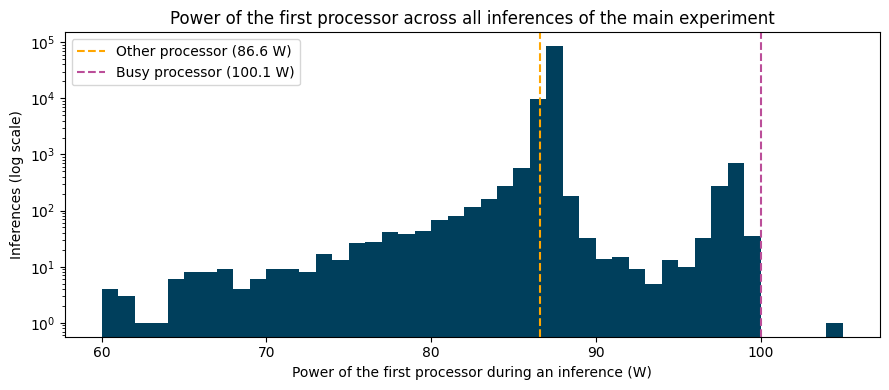

In [12]:
stable = inferences[inferences["time"] >= 5]
power0 = stable["cpu"] / stable["time"]

tolerance = 3  # W
near_other = (power0 - OTHER_WATTS).abs() <= tolerance
near_busy = (power0 - BUSY_WATTS).abs() <= tolerance
print(f"First processor in the 'other' state (~{OTHER_WATTS:.0f} W): {100 * near_other.mean():.1f}% of the inferences")
print(f"First processor in the 'busy' state  (~{BUSY_WATTS:.0f} W): {100 * near_busy.mean():.1f}% of the inferences")
print(f"In neither state: {100 * (~near_other & ~near_busy).mean():.1f}%")

per_model = stable.assign(power=power0).groupby("model")["power"].median()
print(f"\nMedian power of the first processor per model: {per_model.min():.1f} W to {per_model.max():.1f} W")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(power0, bins=[60 + i for i in range(46)], color="#003f5c")
ax.axvline(OTHER_WATTS, color="#ffa600", linestyle="--", label=f"Other processor ({OTHER_WATTS:.1f} W)")
ax.axvline(BUSY_WATTS, color="#bb4e99", linestyle="--", label=f"Busy processor ({BUSY_WATTS:.1f} W)")
ax.set_yscale("log")
ax.set_xlabel("Power of the first processor during an inference (W)")
ax.set_ylabel("Inferences (log scale)")
ax.set_title("Power of the first processor across all inferences of the main experiment")
ax.legend()
plt.tight_layout()
plt.show()

### Effect on the results

The table below shows how the total energy of each model changes, from the values originally recorded to the corrected ones. Fix 1 mostly affects reasoning models, which have the longest inferences. Fix 2 affects every model by a similar proportion, since it adds a nearly constant power for the whole duration of the inference.

In [13]:
per_model = runs.groupby("model").agg(
    recorded=("recorded_total_joules", "sum"),
    recorded_cpu=("recorded_cpu_joules", "sum"),
    cpu=("total_inference_cpu_joules", "sum"),
    cpu1=("total_inference_cpu1_joules_estimated", "sum"),
    dram1=("total_inference_dram1_joules_estimated", "sum"),
    corrected=("total_inference_joules", "sum"),
    gpu=("total_inference_gpu_joules", "sum"),
)
effect = pd.DataFrame({
    "fix 1 (%)": 100 * (per_model["cpu"] - per_model["cpu1"] - per_model["recorded_cpu"]) / per_model["recorded"],
    "fix 2 (%)": 100 * (per_model["cpu1"] + per_model["dram1"]) / per_model["recorded"],
    "total (%)": 100 * (per_model["corrected"] / per_model["recorded"] - 1),
    "GPU share of corrected total (%)": 100 * per_model["gpu"] / per_model["corrected"],
}).sort_values("total (%)", ascending=False)

total_recorded, total_corrected = per_model["recorded"].sum(), per_model["corrected"].sum()
print(f"Total energy of the experiment: {total_recorded / 1e6:.0f} MJ recorded -> {total_corrected / 1e6:.0f} MJ corrected (+{100 * (total_corrected / total_recorded - 1):.1f}%)")
effect.round(1)

Total energy of the experiment: 1443 MJ recorded -> 2075 MJ corrected (+43.8%)


,fix 1 (%),fix 2 (%),total (%),GPU share of corrected total (%)
model,,,,
mistralai/Ministral-3-14B-Reasoning-2512,21.1,33.8,54.9,58.9
microsoft/Phi-4-reasoning,19.6,33.3,52.9,58.9
deepseek-ai/DeepSeek-R1-Distill-Qwen-14B,17.5,32.8,50.3,58.9
Qwen/Qwen3.5-9B (Thinking Mode),16.9,33.0,49.9,58.5
Qwen/Qwen3-14B (Thinking Mode),16.9,32.6,49.5,58.9
deepseek-ai/DeepSeek-R1-0528-Qwen3-8B,14.8,32.2,47.1,58.7
Qwen/Qwen3-8B (Thinking Mode),13.9,32.1,46.0,58.6
mistralai/Ministral-3-8B-Reasoning-2512,14.0,31.9,45.9,58.7
Qwen/Qwen3.5-4B (Thinking Mode),12.6,32.2,44.8,58.1


### GPU energy and total energy rank the models in the same way

The analysis uses the efficiency metrics based on the GPU energy, which was measured directly and needed no correction. The comparison below shows that this choice does not change the conclusions: ranking the models by accuracy per joule using the GPU energy, or using the corrected total energy of the system, gives almost the same order.

In [14]:
by_model = runs.groupby("model")[["accuracy_per_gpu_joule", "accuracy_per_joule"]].mean()
gpu_rank = by_model["accuracy_per_gpu_joule"].rank(ascending=False)
total_rank = by_model["accuracy_per_joule"].rank(ascending=False)
difference = (gpu_rank - total_rank).abs()

print(f"Models: {len(by_model)}")
print(f"Models in a different position: {int((difference > 0).sum())}")
print(f"Largest change of position: {int(difference.max())}")
print(f"Correlation between the two rankings: {gpu_rank.corr(total_rank):.4f}")

Models: 53
Models in a different position: 15
Largest change of position: 2
Correlation between the two rankings: 0.9990
